In [2]:
# Install required packages (run once)
%pip install scanpy anndata scrublet celltypist xgboost shap gseapy scikit-learn tensorflow matplotlib seaborn -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import scanpy as sc
import anndata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sc.settings.verbosity = 1
np.random.seed(42)

In [4]:
DATA_PATH = r"C:\Users\user\OneDrive\Documents\project\pbmc_unsorted_10k_raw_feature_bc_matrix.h5"

adata = sc.read_10x_h5(DATA_PATH)
adata.var_names_make_unique()
print(adata)

AnnData object with n_obs × n_vars = 731132 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'interval'


In [5]:
sc.pp.filter_cells(adata, min_counts=500)
sc.pp.filter_genes(adata, min_cells=3)

print(adata.shape)

(12149, 27543)


In [6]:
adata.var['mt']   = adata.var_names.str.startswith('MT-')
adata.var['ribo'] = adata.var_names.str.startswith(('RPS', 'RPL'))
adata.var['hb']   = adata.var_names.str.contains('^HB[^P]', regex=True)

sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo', 'hb'], inplace=True, percent_top=None)

print(adata)

AnnData object with n_obs × n_vars = 12149 × 27543
    obs: 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'


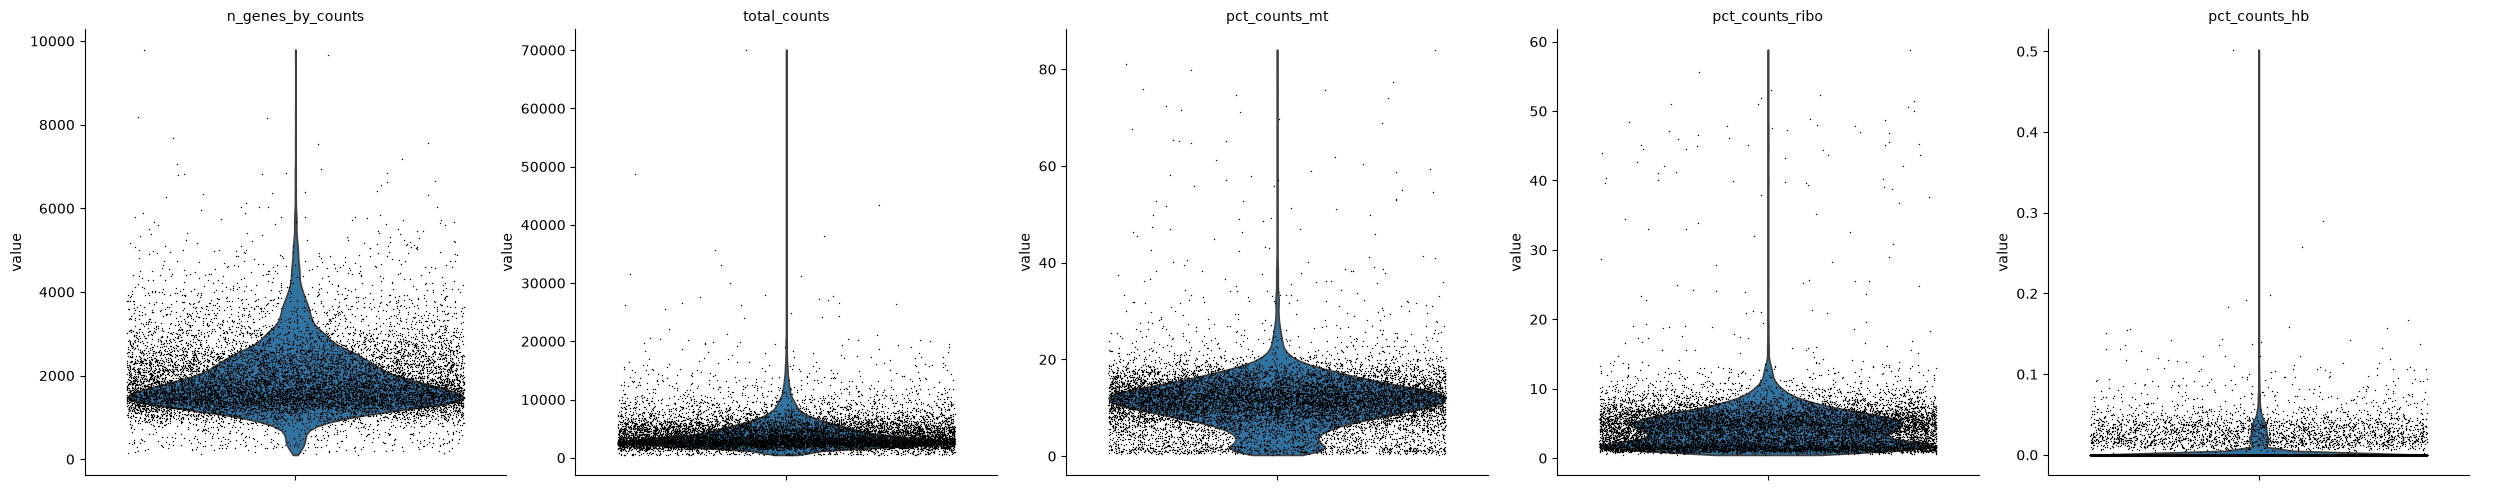

In [7]:
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt',
                      'pct_counts_ribo', 'pct_counts_hb'],
             jitter=0.4, multi_panel=True)

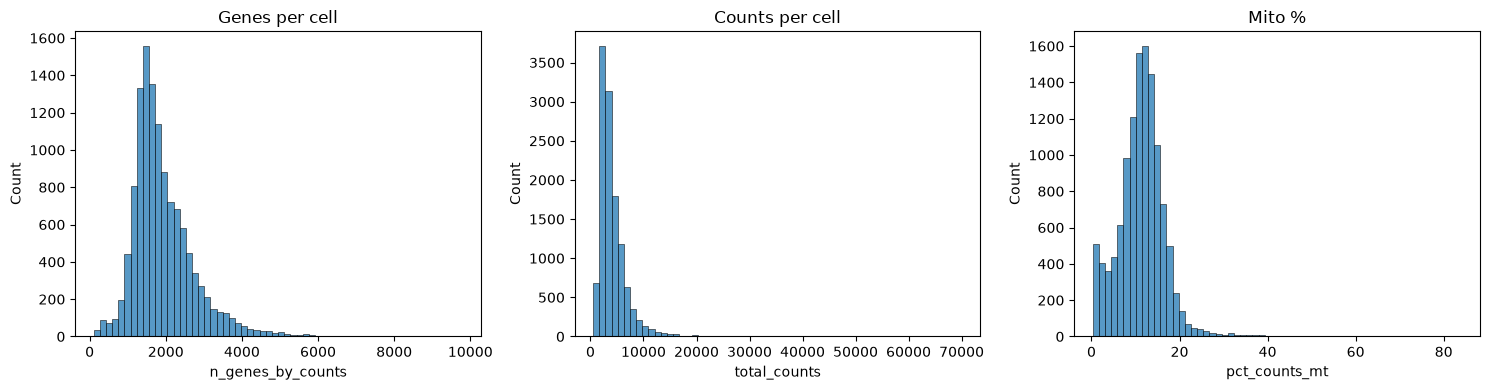

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(adata.obs['n_genes_by_counts'], bins=60, ax=axes[0]); axes[0].set_title('Genes per cell')
sns.histplot(adata.obs['total_counts'], bins=60, ax=axes[1]); axes[1].set_title('Counts per cell')
sns.histplot(adata.obs['pct_counts_mt'], bins=60, ax=axes[2]); axes[2].set_title('Mito %')
plt.tight_layout()
plt.show()

In [9]:
adata_qc_all = adata.copy()

adata = adata[(adata.obs['n_genes_by_counts'] > 200) &
              (adata.obs['n_genes_by_counts'] < 6000) &
              (adata.obs['pct_counts_mt'] < 15)].copy()
print(adata.shape)

(9715, 27543)


In [10]:
import scrublet as scr

scrub = scr.Scrublet(adata.X)
doublet_scores, predicted_doublets = scrub.scrub_doublets()

adata.obs['doublet_score'] = doublet_scores
adata.obs['predicted_doublet'] = predicted_doublets

print("Doublets detected:", adata.obs['predicted_doublet'].sum())

adata = adata[~adata.obs['predicted_doublet']].copy()
print("Cells remaining:", adata.n_obs)

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.18
Detected doublet rate = 14.7%
Estimated detectable doublet fraction = 72.6%
Overall doublet rate:
	Expected   = 10.0%
	Estimated  = 20.2%
Elapsed time: 29.6 seconds
Doublets detected: 1424
Cells remaining: 8291


In [11]:
adata.layers['counts'] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

print(adata)

AnnData object with n_obs × n_vars = 8291 × 27543
    obs: 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    layers: 'counts'


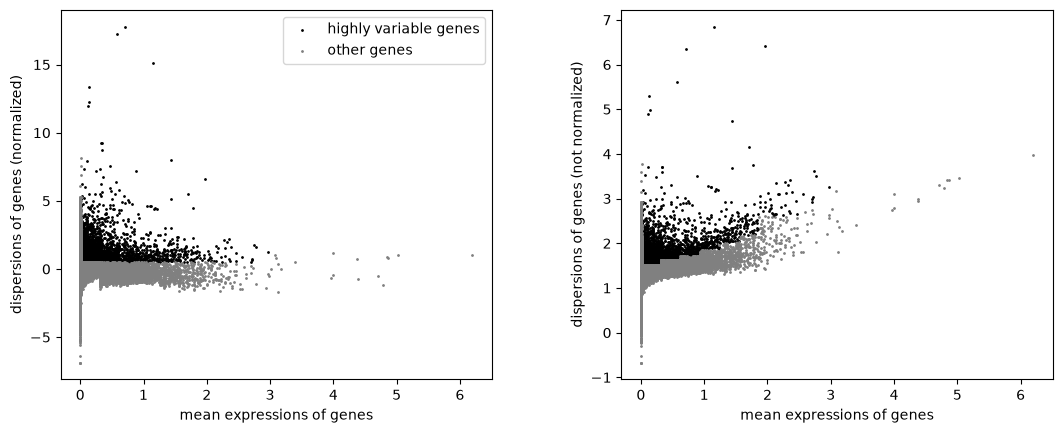

Number of HVGs: 4170


In [12]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata)
print("Number of HVGs:", adata.var['highly_variable'].sum())

In [13]:
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
print(adata)

AnnData object with n_obs × n_vars = 8291 × 4170
    obs: 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'
    layers: 'counts'


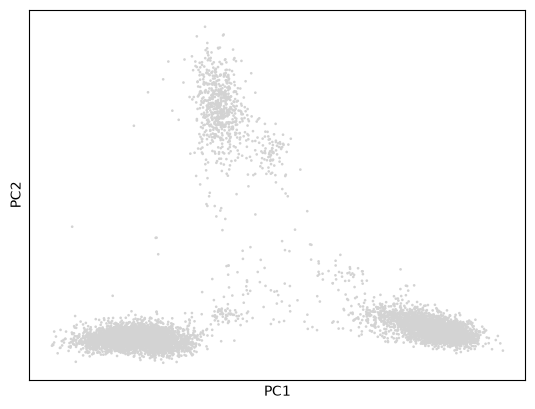

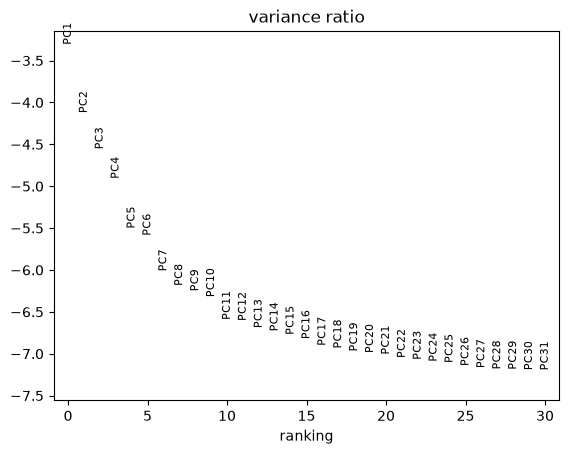

In [14]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca(adata)
sc.pl.pca_variance_ratio(adata, log=True)

In [15]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata)
sc.tl.tsne(adata)

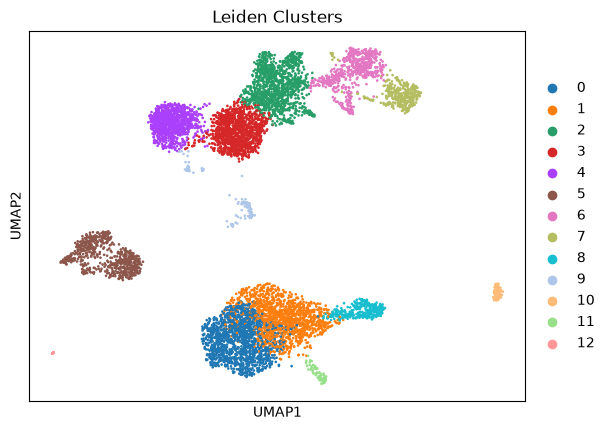

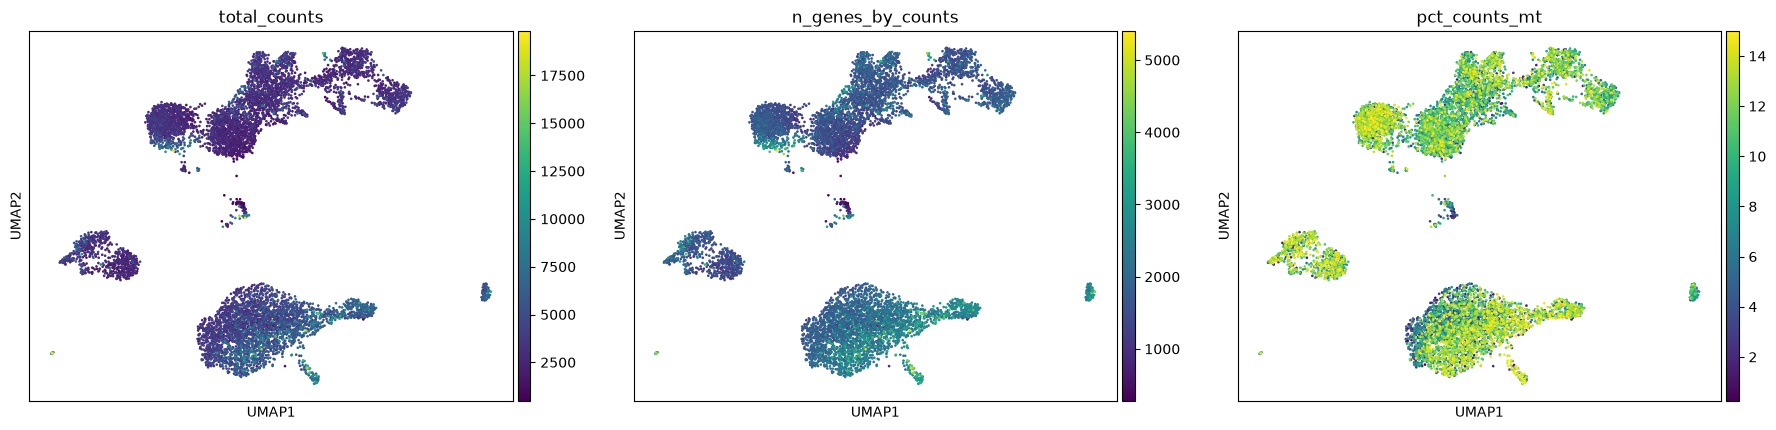

In [16]:
sc.tl.leiden(adata, resolution=0.5)

sc.pl.umap(adata, color=['leiden'], title='Leiden Clusters')
sc.pl.umap(adata, color=['total_counts', 'n_genes_by_counts', 'pct_counts_mt'])

In [17]:
%pip install celltypist

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


📂 Storing models in C:\Users\user\.celltypist\data\models
💾 Total models to download: 1
⏩ Skipping [1/1]: Immune_All_Low.pkl (file exists)
🔬 Input data has 8291 cells and 27543 genes
🔗 Matching reference genes in the model
🧬 5840 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


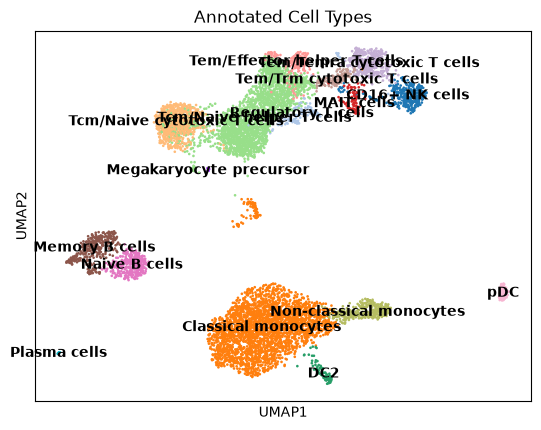

cell_type
Classical monocytes            2774
Tcm/Naive helper T cells       2279
Tcm/Naive cytotoxic T cells     824
Tem/Temra cytotoxic T cells     351
Naive B cells                   336
CD16+ NK cells                  325
Memory B cells                  320
Non-classical monocytes         314
Tem/Effector helper T cells     207
Regulatory T cells              139
Tem/Trm cytotoxic T cells       133
MAIT cells                      101
pDC                              87
DC2                              80
Plasma cells                     14
Megakaryocyte precursor           7
Name: count, dtype: int64


In [18]:
import celltypist
from celltypist import models

models.download_models(model=['Immune_All_Low.pkl'])

# CellTypist expects log1p-normalized-to-10k data with all genes (use adata.raw)
adata_full = adata.raw.to_adata()
predictions = celltypist.annotate(adata_full, model='Immune_All_Low.pkl', majority_voting=True)

adata.obs['cell_type'] = predictions.predicted_labels['majority_voting'].values

sc.pl.umap(adata, color='cell_type', legend_loc='on data', title='Annotated Cell Types')
print(adata.obs['cell_type'].value_counts())

In [19]:
adata_qc_all.obs['cell_quality'] = np.where(
    (adata_qc_all.obs['n_genes_by_counts'] > 200) &
    (adata_qc_all.obs['n_genes_by_counts'] < 6000) &
    (adata_qc_all.obs['pct_counts_mt'] < 15),
    'Good', 'Bad'
)

adata_qc_all.obs['gene_complexity']  = adata_qc_all.obs['n_genes_by_counts'] / adata_qc_all.obs['total_counts']
adata_qc_all.obs['log_total_counts'] = np.log1p(adata_qc_all.obs['total_counts'])
adata_qc_all.obs['mt_ratio']         = adata_qc_all.obs['pct_counts_mt'] / 100
adata_qc_all.obs['ribo_ratio']       = adata_qc_all.obs['pct_counts_ribo'] / 100
adata_qc_all.obs['mt_ribo_ratio']    = adata_qc_all.obs['mt_ratio'] / (adata_qc_all.obs['ribo_ratio'] + 1e-6)

feature_cols = [
    'total_counts', 'pct_counts_ribo', 'pct_counts_hb',
    'gene_complexity', 'log_total_counts', 'ribo_ratio', 'mt_ribo_ratio'
]

X = adata_qc_all.obs[feature_cols].copy()
y = adata_qc_all.obs['cell_quality'].copy()

print(X.shape)
print(y.value_counts())

(12149, 7)
cell_quality
Good    9715
Bad     2434
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(X_train.shape, X_test.shape)

(9719, 7) (2430, 7)


In [21]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 20, None]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid, cv=cv, scoring='f1_macro', n_jobs=-1
)
rf_grid.fit(X_train, y_train)

rf_best = rf_grid.best_estimator_
print("Best RF params:", rf_grid.best_params_)

rf_cv_scores = cross_val_score(rf_best, X_train, y_train, cv=cv, scoring='accuracy')
print("RF 5-fold CV accuracy: %.4f +/- %.4f" % (rf_cv_scores.mean(), rf_cv_scores.std()))

Best RF params: {'max_depth': 20, 'n_estimators': 100}
RF 5-fold CV accuracy: 0.9742 +/- 0.0030


In [22]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc  = le.transform(y_test)

xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 8],
    'learning_rate': [0.01, 0.1, 0.2]
}

xgb_grid = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss'),
    xgb_param_grid, cv=cv, scoring='f1_macro', n_jobs=-1
)
xgb_grid.fit(X_train, y_train_enc)

xgb_best = xgb_grid.best_estimator_
print("Best XGBoost params:", xgb_grid.best_params_)

Best XGBoost params: {'learning_rate': 0.2, 'max_depth': 8, 'n_estimators': 300}


In [23]:
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

nn_model = tf.keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

nn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = nn_model.fit(
    X_train_scaled, y_train_enc,
    validation_split=0.1,
    epochs=30, batch_size=32, verbose=0
)

print("Final training accuracy:", history.history['accuracy'][-1])
print("Final validation accuracy:", history.history['val_accuracy'][-1])

TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.


Final training accuracy: 0.9751914739608765
Final validation accuracy: 0.9855967164039612


In [24]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
)

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'AUC': roc_auc_score(y_true, y_prob)
    }

results = []

# --- Random Forest ---
rf_pred = rf_best.predict(X_test)
rf_pred_enc = le.transform(rf_pred)
rf_prob = rf_best.predict_proba(X_test)[:, list(rf_best.classes_).index('Good')]
results.append(evaluate_model('Random Forest', y_test_enc, rf_pred_enc, rf_prob))

# --- XGBoost ---
xgb_pred_enc = xgb_best.predict(X_test)
xgb_prob = xgb_best.predict_proba(X_test)[:, 1]
results.append(evaluate_model('XGBoost', y_test_enc, xgb_pred_enc, xgb_prob))

# --- Neural Network ---
nn_prob = nn_model.predict(X_test_scaled).ravel()
nn_pred_enc = (nn_prob > 0.5).astype(int)
results.append(evaluate_model('Neural Network', y_test_enc, nn_pred_enc, nn_prob))

results_df = pd.DataFrame(results)
print(results_df)

76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
            Model  Accuracy  Precision    Recall        F1       AUC
0   Random Forest  0.981481   0.983690  0.993309  0.988476  0.997878
1         XGBoost  0.987243   0.990760  0.993309  0.992033  0.998586
2  Neural Network  0.986008   0.993792  0.988677  0.991228  0.998440


In [25]:
from sklearn.metrics import classification_report

print("Random Forest:\n", classification_report(y_test_enc, rf_pred_enc, target_names=le.classes_))
print("\nXGBoost:\n", classification_report(y_test_enc, xgb_pred_enc, target_names=le.classes_))
print("\nNeural Network:\n", classification_report(y_test_enc, nn_pred_enc, target_names=le.classes_))

Random Forest:
               precision    recall  f1-score   support

         Bad       0.97      0.93      0.95       487
        Good       0.98      0.99      0.99      1943

    accuracy                           0.98      2430
   macro avg       0.98      0.96      0.97      2430
weighted avg       0.98      0.98      0.98      2430


XGBoost:
               precision    recall  f1-score   support

         Bad       0.97      0.96      0.97       487
        Good       0.99      0.99      0.99      1943

    accuracy                           0.99      2430
   macro avg       0.98      0.98      0.98      2430
weighted avg       0.99      0.99      0.99      2430


Neural Network:
               precision    recall  f1-score   support

         Bad       0.96      0.98      0.97       487
        Good       0.99      0.99      0.99      1943

    accuracy                           0.99      2430
   macro avg       0.97      0.98      0.98      2430
weighted avg       0.99      

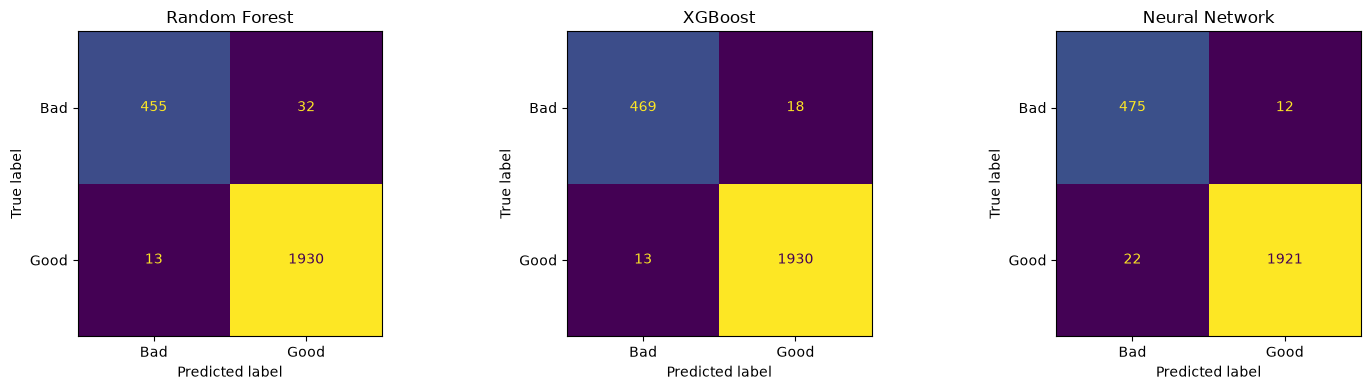

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, [('Random Forest', rf_pred_enc),
                                    ('XGBoost', xgb_pred_enc),
                                    ('Neural Network', nn_pred_enc)]):
    cm = confusion_matrix(y_test_enc, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Bad', 'Good']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

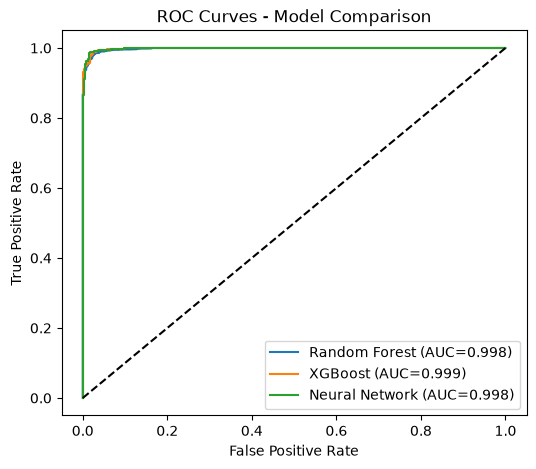

In [27]:
# ROC curves
plt.figure(figsize=(6, 5))
for name, prob in [('Random Forest', rf_prob), ('XGBoost', xgb_prob), ('Neural Network', nn_prob)]:
    fpr, tpr, _ = roc_curve(y_test_enc, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison')
plt.legend()
plt.show()

Best model by F1: XGBoost


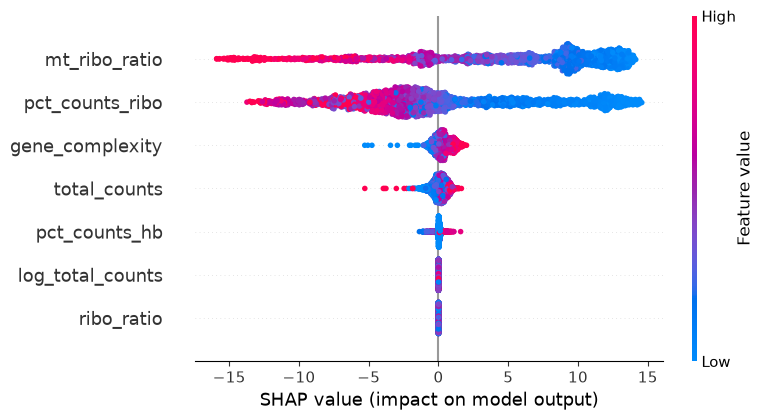

In [28]:
import shap

best_model_name = results_df.sort_values('F1', ascending=False).iloc[0]['Model']
print("Best model by F1:", best_model_name)

# Using XGBoost as the tree-based reference explainer (swap to rf_best if RF wins)
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=True)

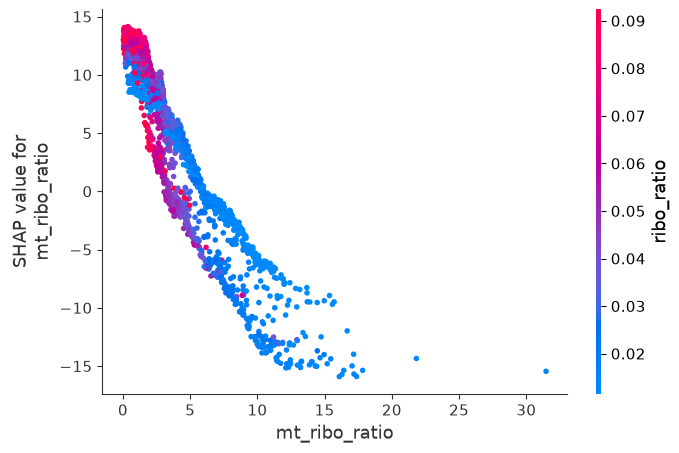

In [29]:
# SHAP dependence plot for the top feature
top_feature = X_test.columns[np.argsort(np.abs(shap_values).mean(0))[-1]]
shap.dependence_plot(top_feature, shap_values, X_test)

                Configuration        F1       AUC
0           A. All 7 features  0.992033  0.998586
1    B. Without mt_ribo_ratio  0.899524  0.836957
2  C. Without pct_counts_ribo  0.992033  0.998586
3             D. Without both  0.897908  0.837407


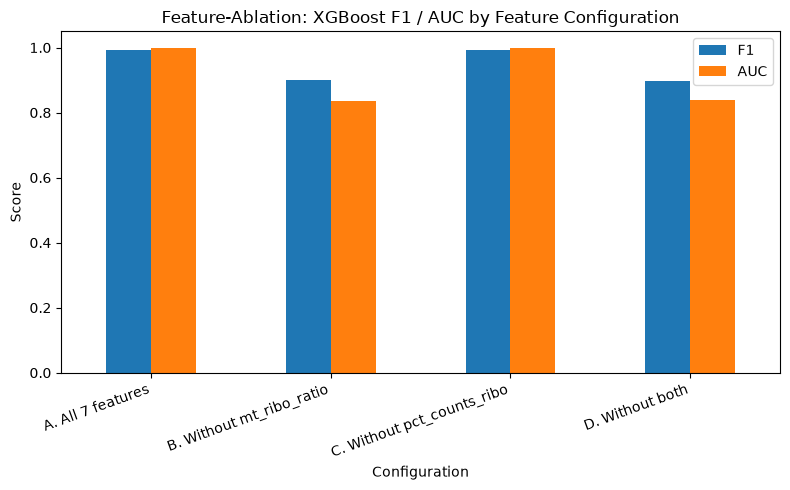


Saved: Feature_Ablation_Results.csv


In [30]:
# Feature-ablation experiment: A (all 7) / B (no mt_ribo_ratio) / C (no pct_counts_ribo) / D (no both)

ablation_configs = {
    'A. All 7 features':              feature_cols,
    'B. Without mt_ribo_ratio':        [f for f in feature_cols if f != 'mt_ribo_ratio'],
    'C. Without pct_counts_ribo':      [f for f in feature_cols if f != 'pct_counts_ribo'],
    'D. Without both':                 [f for f in feature_cols if f not in ('mt_ribo_ratio', 'pct_counts_ribo')],
}

ablation_results = []

for config_name, cols in ablation_configs.items():
    # Reuse the best hyperparameters already found for the full feature set,
    # so every configuration is compared on equal footing rather than re-tuned individually.
    model = XGBClassifier(**xgb_grid.best_params_, random_state=42, eval_metric='logloss')
    model.fit(X_train[cols], y_train_enc)

    pred = model.predict(X_test[cols])
    prob = model.predict_proba(X_test[cols])[:, 1]

    ablation_results.append({
        'Configuration': config_name,
        'Features used': ', '.join(cols),
        'F1': f1_score(y_test_enc, pred),
        'AUC': roc_auc_score(y_test_enc, prob),
    })

ablation_df = pd.DataFrame(ablation_results)
print(ablation_df[['Configuration', 'F1', 'AUC']])

ablation_df.set_index('Configuration')[['F1', 'AUC']].plot.bar(figsize=(8, 5), ylim=(0, 1.05))
plt.title('Feature-Ablation: XGBoost F1 / AUC by Feature Configuration')
plt.ylabel('Score')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

ablation_df.to_csv('Feature_Ablation_Results.csv', index=False)
print("\nSaved: Feature_Ablation_Results.csv")

            Feature  MeanAbsSHAP
6     mt_ribo_ratio     7.757156
1   pct_counts_ribo     5.324680
3   gene_complexity     0.537458
0      total_counts     0.409674
2     pct_counts_hb     0.126274
4  log_total_counts     0.000000
5        ribo_ratio     0.000000


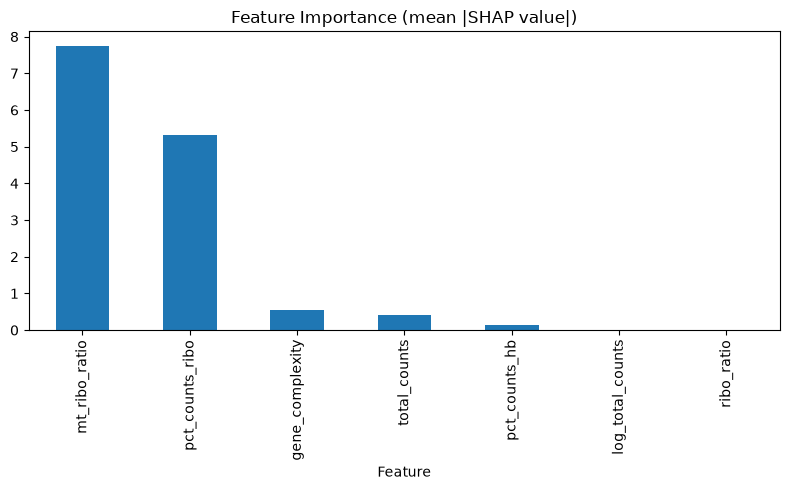

In [31]:
# Feature importance table
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'MeanAbsSHAP': np.abs(shap_values).mean(0)
}).sort_values('MeanAbsSHAP', ascending=False)

print(importance_df)
importance_df.plot.bar(x='Feature', y='MeanAbsSHAP', figsize=(8, 5), legend=False)
plt.title('Feature Importance (mean |SHAP value|)')
plt.tight_layout()
plt.show()

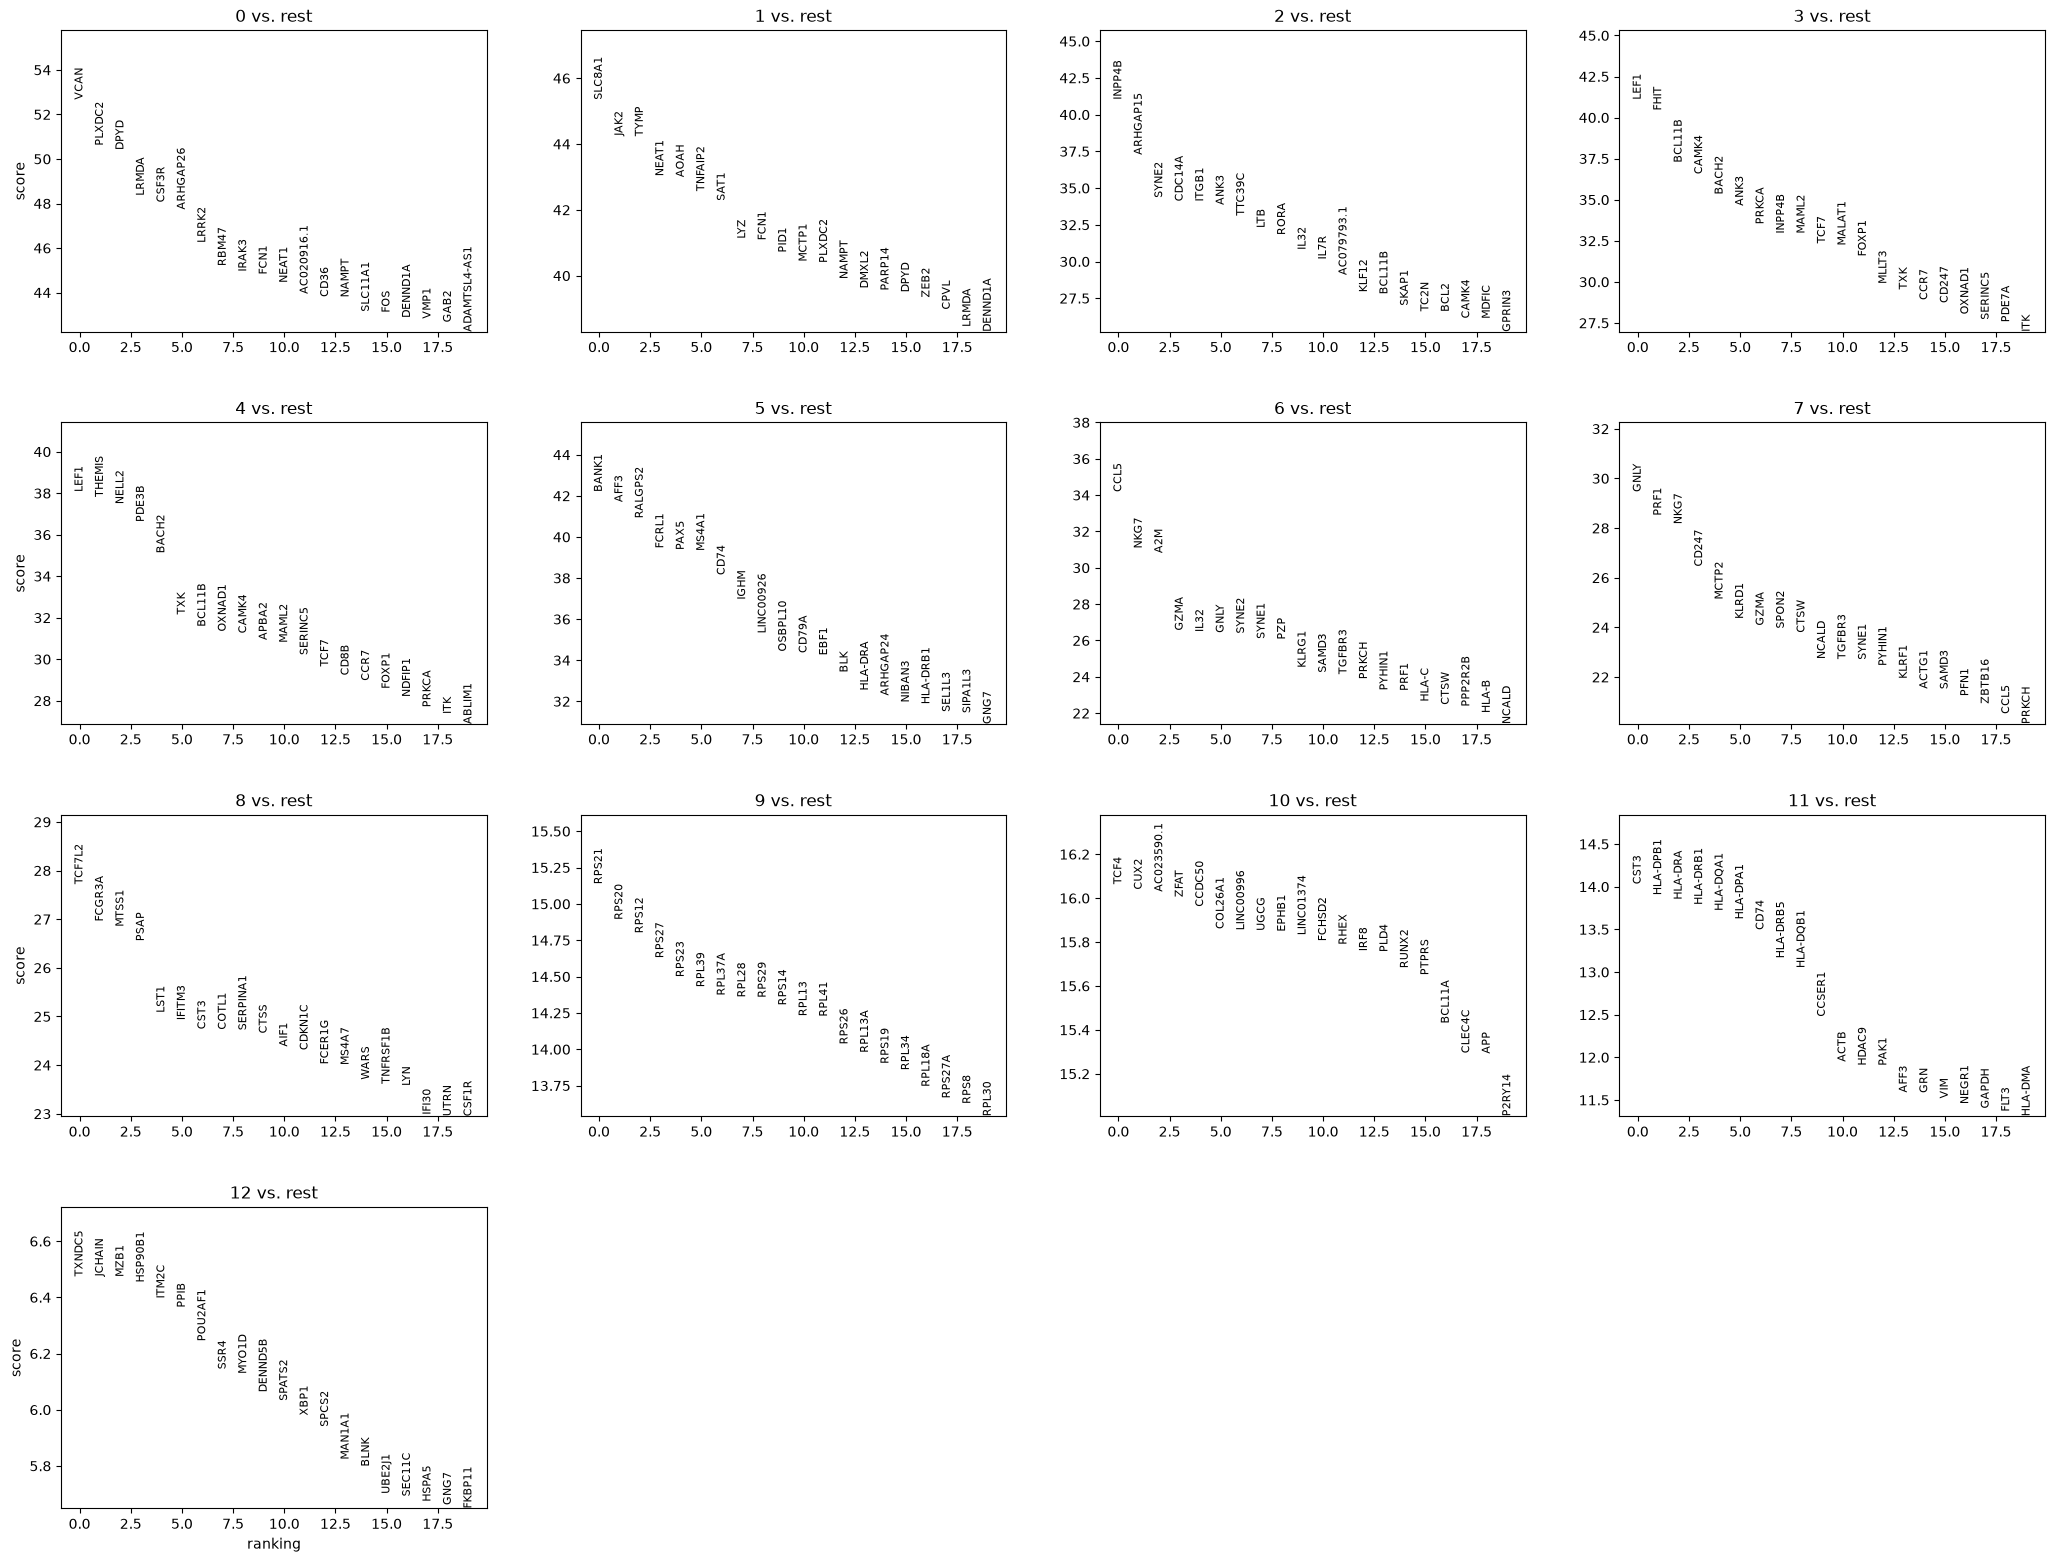

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,VCAN,52.661648,4.939284,0.0,0.0
1,0,PLXDC2,50.599358,4.535885,0.0,0.0
2,0,DPYD,50.403755,2.809520,0.0,0.0
3,0,LRMDA,48.349949,4.199605,0.0,0.0
4,0,CSF3R,48.053299,4.021254,0.0,0.0
5,0,ARHGAP26,47.728836,3.118791,0.0,0.0
6,0,LRRK2,46.234192,3.810905,0.0,0.0
7,0,RBM47,45.192654,3.708862,0.0,0.0
8,0,IRAK3,44.943310,3.681126,0.0,0.0
9,0,FCN1,44.813107,3.433908,0.0,0.0


In [32]:
sc.tl.rank_genes_groups(adata, groupby='leiden', method='wilcoxon')
sc.pl.rank_genes_groups(adata, n_genes=20, sharey=False)

marker_df = sc.get.rank_genes_groups_df(adata, group=None)
marker_df.to_csv('Marker_Genes.csv', index=False)
marker_df.head(20)

In [33]:
%pip install gseapy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
import gseapy as gp

# Take top marker genes across clusters (adjust group / n as needed)
top_genes = (marker_df.sort_values('pvals_adj')
                       .groupby('group')['names']
                       .head(20)
                       .unique()
                       .tolist())

go_results = gp.enrichr(gene_list=top_genes, gene_sets='GO_Biological_Process_2021',
                        outdir=None, organism='human')
kegg_results = gp.enrichr(gene_list=top_genes, gene_sets='KEGG_2021_Human',
                          outdir=None, organism='human')
reactome_results = gp.enrichr(gene_list=top_genes, gene_sets='Reactome_2022',
                              outdir=None, organism='human')

print(go_results.results.head(10))
print(kegg_results.results.head(10))
print(reactome_results.results.head(10))

                     Gene_set  \
0  GO_Biological_Process_2021   
1  GO_Biological_Process_2021   
2  GO_Biological_Process_2021   
3  GO_Biological_Process_2021   
4  GO_Biological_Process_2021   
5  GO_Biological_Process_2021   
6  GO_Biological_Process_2021   
7  GO_Biological_Process_2021   
8  GO_Biological_Process_2021   
9  GO_Biological_Process_2021   

                                                Term Overlap       P-value  \
0               protein targeting to ER (GO:0045047)  21/103  2.141396e-21   
1  SRP-dependent cotranslational protein targetin...   19/90  9.047903e-20   
2               cytoplasmic translation (GO:0002181)   19/93  1.762042e-19   
3  cotranslational protein targeting to membrane ...   19/94  2.188250e-19   
4  nuclear-transcribed mRNA catabolic process, no...  19/113  8.604647e-18   
5          peptide biosynthetic process (GO:0043043)  19/162  8.527554e-15   
6  nuclear-transcribed mRNA catabolic process (GO...  19/171  2.328584e-14   
7   cytokine

In [35]:
kegg_results = gp.enrichr(gene_list=top_genes, gene_sets='KEGG_2021_Human',
                          outdir=None, organism='human')
reactome_results = gp.enrichr(gene_list=top_genes, gene_sets='Reactome_2022',
                              outdir=None, organism='human')

print(kegg_results.results.head(10))
print(reactome_results.results.head(10))

          Gene_set                                 Term Overlap       P-value  \
0  KEGG_2021_Human  Antigen processing and presentation   15/78  3.288957e-15   
1  KEGG_2021_Human                             Ribosome  19/158  5.344591e-15   
2  KEGG_2021_Human                  Coronavirus disease  21/232  5.878794e-14   
3  KEGG_2021_Human            Graft-versus-host disease   11/42  4.458199e-13   
4  KEGG_2021_Human                    Viral myocarditis   12/60  1.245754e-12   
5  KEGG_2021_Human                  Allograft rejection   10/38  5.038650e-12   
6  KEGG_2021_Human             Type I diabetes mellitus   10/43  1.952040e-11   
7  KEGG_2021_Human           Hematopoietic cell lineage   13/99  3.857829e-11   
8  KEGG_2021_Human                            Phagosome  15/152  7.601889e-11   
9  KEGG_2021_Human           Autoimmune thyroid disease   10/53  1.811322e-10   

   Adjusted P-value  Old P-value  Old Adjusted P-value  Odds Ratio  \
0      5.825605e-13            0      

In [36]:
print(reactome_results.results.head(10))

        Gene_set                                               Term Overlap  \
0  Reactome_2022  SRP-dependent Cotranslational Protein Targetin...  20/108   
1  Reactome_2022              Peptide Chain Elongation R-HSA-156902   17/86   
2  Reactome_2022     Eukaryotic Translation Elongation R-HSA-156842   17/90   
3  Reactome_2022     Eukaryotic Translation Termination R-HSA-72764   17/90   
4  Reactome_2022             Selenocysteine Synthesis R-HSA-2408557   17/90   
5  Reactome_2022                Viral mRNA Translation R-HSA-192823   17/90   
6  Reactome_2022  Nonsense Mediated Decay (NMD) Independent Of E...   17/92   
7  Reactome_2022  Formation Of A Pool Of Free 40S Subunits R-HSA...   17/98   
8  Reactome_2022  Response Of EIF2AK4 (GCN2) To Amino Acid Defic...   17/98   
9  Reactome_2022  L13a-mediated Translational Silencing Of Cerul...  17/108   

        P-value  Adjusted P-value  Old P-value  Old Adjusted P-value  \
0  1.523359e-19      1.247631e-16            0            

In [37]:
results_df.to_csv('Model_Comparison_raw10k.csv', index=False)
importance_df.to_csv('Feature_Importance_raw10k.csv', index=False)
adata.write('AI_Powered_scRNAseq_Final_raw10k.h5ad')

print("Pipeline completed successfully.")

Pipeline completed successfully.


In [38]:
adata.obs['cell_quality'] = adata_qc_all.obs.loc[adata.obs_names, 'cell_quality']

pd.crosstab(adata.obs['cell_type'], adata.obs['cell_quality'])

cell_quality,Good
cell_type,
CD16+ NK cells,325
Classical monocytes,2774
DC2,80
MAIT cells,101
Megakaryocyte precursor,7
Memory B cells,320
Naive B cells,336
Non-classical monocytes,314
Plasma cells,14


In [40]:
cols=['total_counts','pct_counts_ribo','pct_counts_hb','gene_complexity',
      'log_total_counts','ribo_ratio','mt_ribo_ratio','cell_quality']
adata_qc_all.obs[cols].to_csv('features_C.csv')